## Objective
The objective of this project is to build an AdaBoost Regression model for predicting diamond prices using characteristics such as carat, cut, colour, clarity, depth, table, and physical dimensions. The dataset will be examined and prepared before developing the baseline and tuned regression models. Model performance will be evaluated using regression metrics such as MSE, MAE, RMSE, MAPE, and R² score. An appropriate primary evaluation metric should be selected according to the problem statement, target values, and importance of different prediction errors. The selected metric will be used as the scoring measure during hyperparameter tuning and for comparing the baseline and tuned models. Training and testing performance will also be compared using the selected metric to identify possible overfitting. The final model will be selected based on its predictive performance and ability to generalise well to unseen data.

## **Task 1**
- *Import the libraries required for data preparation, modelling, evaluation, and visualisation*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# Data Preparation

## **Task 2**

- *Load the dataset and display the first few records*
- *Check the dataset shape, data types, and column names*
- *Check for missing values and duplicate records*

In [2]:
diamonds = pd.read_csv('../data/diamonds_dataset.csv')
# The raw file has two columns named "depth": total depth percentage and the physical z-dimension (mm).
# pandas renames the second to "depth.1"; give both unambiguous names.
diamonds = diamonds.rename(columns={'depth': 'depth_pct', 'depth.1': 'z_mm', 'length': 'x_mm', 'width': 'y_mm'})
display(diamonds.head())
print('Shape:', diamonds.shape)
print('\nData types:\n', diamonds.dtypes.to_string())
print('\nMissing values:', int(diamonds.isna().sum().sum()), '| Duplicate rows:', diamonds.duplicated().sum())
print('Zero dimensions (x, y, z):', int((diamonds[['x_mm', 'y_mm', 'z_mm']] == 0).any(axis=1).sum()))
display(diamonds['price'].describe().round(0).to_frame().T)

,carat,cut,color,clarity,depth_pct,table,price,x_mm,y_mm,z_mm
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Shape: (53772, 10)

Data types:
 carat        float64
cut              str
color            str
clarity          str
depth_pct    float64
table        float64
price          int64
x_mm         float64
y_mm         float64
z_mm         float64

Missing values: 0 | Duplicate rows: 0
Zero dimensions (x, y, z): 0


,count,mean,std,min,25%,50%,75%,max
price,53772.0,3931.0,3986.0,326.0,951.0,2401.0,5324.0,18823.0


**Observation:** 53,772 diamonds, with no missing values, duplicates or zero dimensions. The raw file had two columns both named `depth` (depth percentage and the z-dimension in mm). They are renamed so they can't be confused. Price is right-skewed: median USD 2,401, mean USD 3,931, maximum USD 18,823.

## **Task 3**
- *Separate the predictor variables and the target variable*

In [3]:
X = diamonds.drop(columns='price')
y = diamonds['price']
CAT_COLS = ['cut', 'color', 'clarity']
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]
print('Categorical:', CAT_COLS); print('Numeric:', NUM_COLS)

Categorical: ['cut', 'color', 'clarity']
Numeric: ['carat', 'depth_pct', 'table', 'x_mm', 'y_mm', 'z_mm']


## **Task 4**
- *Split the feature and target datasets into training and testing sets*

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

Train: (43017, 9) | Test: (10755, 9)


## **Task 5**
- *Encode the categorical features by fitting the encoder on the training data and applying the same transformation to the testing data*

In [5]:
encoder = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT_COLS)],
                            remainder='passthrough', verbose_feature_names_out=False)
X_train_enc = pd.DataFrame(encoder.fit_transform(X_train), columns=encoder.get_feature_names_out(), index=X_train.index)
X_test_enc = pd.DataFrame(encoder.transform(X_test), columns=encoder.get_feature_names_out(), index=X_test.index)
print('Encoded feature count:', X_train_enc.shape[1])

Encoded feature count: 26


# Model Training

## **Task 6**
- *Build and train a baseline AdaBoost Regressor using the training data*
- *Display the baseline model parameters*

In [6]:
baseline_ada = AdaBoostRegressor(random_state=RANDOM_STATE)
baseline_ada.fit(X_train_enc, y_train)
print(pd.Series(baseline_ada.get_params()).to_string())

estimator          None
learning_rate       1.0
loss             linear
n_estimators         50
random_state         42


## **Task 7**
- *Generate predictions for the training and testing datasets using the baseline model*

In [7]:
base_train_pred = baseline_ada.predict(X_train_enc)
base_test_pred = baseline_ada.predict(X_test_enc)

## **Task 8**
- *Plot the actual and predicted diamond prices for the training and testing datasets using the baseline AdaBoost model*

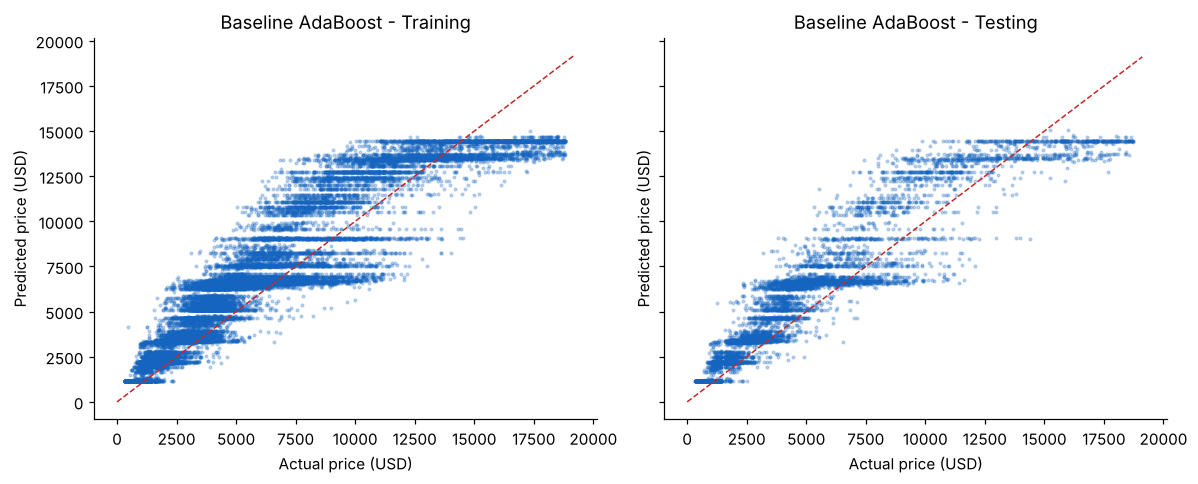

In [8]:
def plot_actual_vs_pred(train_pred, test_pred, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, (split, yt, yp) in zip(axes, [('Training', y_train, train_pred), ('Testing', y_test, test_pred)]):
        ax.scatter(yt, yp, s=3, alpha=0.25, color='#1565C0')
        lim = [0, max(yt.max(), yp.max()) * 1.02]
        ax.plot(lim, lim, '--', color='#C62828', lw=1); ax.set_title(f'{title} - {split}')
        ax.set_xlabel('Actual price (USD)'); ax.set_ylabel('Predicted price (USD)')
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_actual_vs_pred(base_train_pred, base_test_pred, 'Baseline AdaBoost', 'actual_vs_pred_baseline.png')

## **Task 9**
- *Plot the actual and predicted diamond prices for the first 50 testing records using the baseline model*

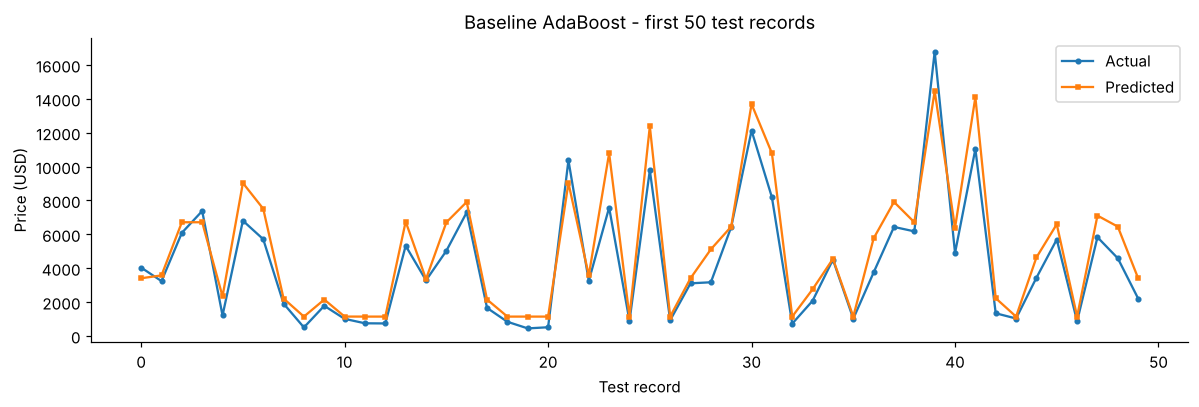

In [9]:
def plot_first_50(test_pred, title, fname):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(range(50), y_test.values[:50], marker='o', ms=3, label='Actual')
    ax.plot(range(50), test_pred[:50], marker='s', ms=3, label='Predicted')
    ax.set_xlabel('Test record'); ax.set_ylabel('Price (USD)'); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_first_50(base_test_pred, 'Baseline AdaBoost - first 50 test records', 'first50_baseline.png')

# Model Interpretation

## **Task 10**
- *Evaluate the baseline model using MSE, MAE, RMSE, MAPE, and R² score for the training and testing datasets*

In [10]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mse),
            'MAPE (%)': 100 * mean_absolute_percentage_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

base_metrics = pd.DataFrame({'Training': regression_metrics(y_train, base_train_pred),
                             'Testing': regression_metrics(y_test, base_test_pred)})
display(base_metrics.round(3))

,Training,Testing
MSE,1917321.883,1935442.757
MAE,1018.277,1027.798
RMSE,1384.674,1391.202
MAPE (%),42.006,42.249
R2,0.880,0.875


## **Task 11** 
- *Calculate the training–testing performance gap of the baseline AdaBoost model using the selected evaluation metric*

In [11]:
# Primary metric: MAPE. Prices span USD 326 to 18,823, and an error of USD 500 matters far more on a
# USD 1,000 stone than on a USD 15,000 one. MAPE measures error relative to price, the way a buyer
# or seller experiences it. RMSE and R2 are reported alongside for scale.
PRIMARY = 'MAPE (%)'
base_gap = base_metrics.loc[PRIMARY, 'Testing'] - base_metrics.loc[PRIMARY, 'Training']
print(f'Baseline {PRIMARY}: train = {base_metrics.loc[PRIMARY, "Training"]:.2f}, '
      f'test = {base_metrics.loc[PRIMARY, "Testing"]:.2f}, gap (test - train) = {base_gap:.2f} points')

Baseline MAPE (%): train = 42.01, test = 42.25, gap (test - train) = 0.24 points


**Observation:** The default AdaBoost (50 trees, learning rate 1.0) has a test MAPE of 42.3% and R² of 0.875. Train and test scores are almost identical (gap 0.24 points), so the model is **underfitting**, not overfitting. Depth-3 trees combined this way are too coarse for prices that range over a factor of 50.

## **Task 12**

- *Identify and visualise the 5 most influential features used by the baseline model*

,Importance
y_mm,0.228
carat,0.178
z_mm,0.147
clarity_I1,0.078
clarity_IF,0.068


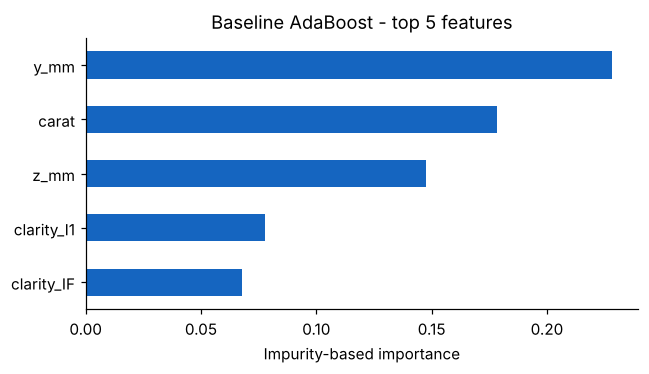

In [12]:
base_imp = pd.Series(baseline_ada.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
display(base_imp.head(5).round(3).to_frame('Importance'))
fig, ax = plt.subplots(figsize=(6, 3.5))
base_imp.head(5)[::-1].plot.barh(ax=ax, color='#1565C0')
ax.set_title('Baseline AdaBoost - top 5 features'); ax.set_xlabel('Impurity-based importance')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance_baseline.png', bbox_inches='tight'); plt.show()

**Observation:** Size dominates: y-dimension (0.228), carat (0.178) and z-dimension (0.147). These three are strongly correlated, so the importance is split between them somewhat arbitrarily. Clarity extremes (I1, IF) are the only quality grades in the top five.

# Hyperparameter Tuning

## **Task 13**
- *Define suitable values for `n_estimators`, `learning_rate`, and `loss`*
- *Select an appropriate scoring metric according to the problem statement and model objective*
- *Tune the AdaBoost Regressor using five-fold cross-validation and the selected scoring metric and display the best hyperparameters and best cross-validation score**
- *Select and train the best estimator as the final AdaBoost model*

In [13]:
param_grid = {'n_estimators': [50, 150], 'learning_rate': [0.1, 0.5, 1.0], 'loss': ['linear', 'square', 'exponential']}
grid = GridSearchCV(AdaBoostRegressor(random_state=RANDOM_STATE), param_grid,
                    scoring='neg_mean_absolute_percentage_error', cv=5, n_jobs=-1)
grid.fit(X_train_enc, y_train)
print('Best hyperparameters:', grid.best_params_)
print(f'Best 5-fold CV MAPE: {-100 * grid.best_score_:.2f}%')
final_ada = grid.best_estimator_
cv_res = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
cv_view = pd.DataFrame(cv_res['params'].tolist()).assign(**{'CV MAPE (%)': (-100 * cv_res['mean_test_score']).values})
display(cv_view.head(6).round(2))

Best hyperparameters: {'learning_rate': 0.1, 'loss': 'linear', 'n_estimators': 50}
Best 5-fold CV MAPE: 24.77%


,learning_rate,loss,n_estimators,CV MAPE (%)
0,0.1,linear,50,24.77
1,0.1,square,50,24.88
2,0.1,exponential,50,25.61
3,0.1,square,150,26.17
4,0.5,square,50,29.51
5,0.1,linear,150,32.87


**Observation:** The best setting is a lower learning rate (0.1) with only 50 trees and linear loss: CV MAPE 24.8%. Adding trees at the same learning rate makes it **worse** (150 trees: 32.9%). AdaBoost.R2 up-weights samples with large absolute errors, which are mostly expensive stones. More rounds therefore push the ensemble further towards the expensive end, at the cost of relative accuracy on cheaper stones.

## **Task 14**
- *Generate predictions for the training and testing datasets using the final AdaBoost model*

In [14]:
final_train_pred = final_ada.predict(X_train_enc)
final_test_pred = final_ada.predict(X_test_enc)

## **Task 15**
- *Plot the actual and predicted diamond prices for the training and testing datasets using the final AdaBoost model*

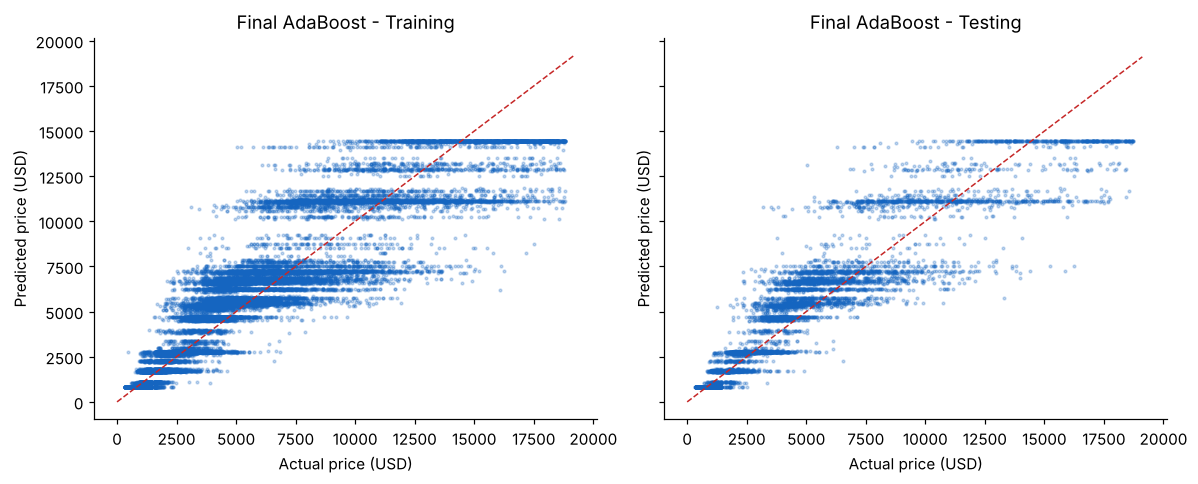

In [15]:
plot_actual_vs_pred(final_train_pred, final_test_pred, 'Final AdaBoost', 'actual_vs_pred_final.png')

## **Task 16**
- *Plot the actual and predicted diamond prices for the first 50 testing records using the final AdaBoost model*

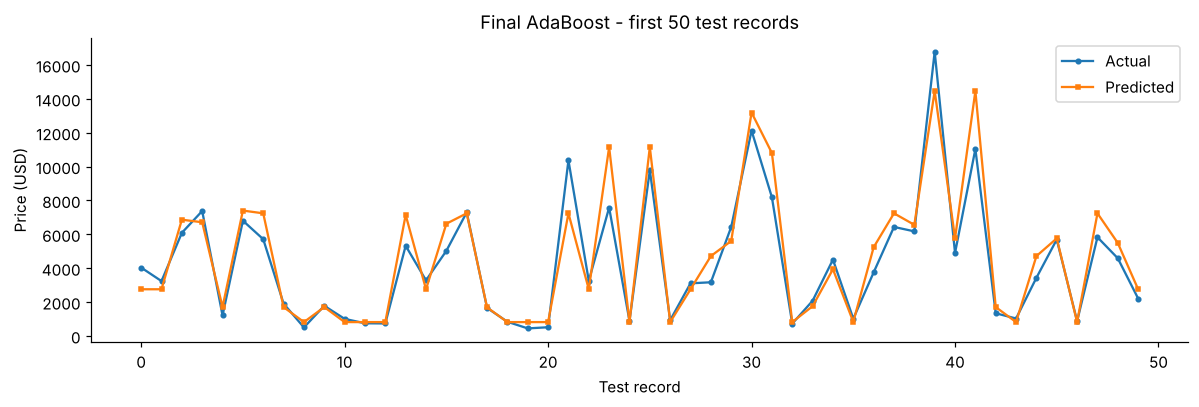

In [16]:
plot_first_50(final_test_pred, 'Final AdaBoost - first 50 test records', 'first50_final.png')

## **Task 17**
- *Evaluate the final model using MSE, MAE, RMSE, MAPE, and R² score for the training and testing datasets*

In [17]:
final_metrics = pd.DataFrame({'Training': regression_metrics(y_train, final_train_pred),
                              'Testing': regression_metrics(y_test, final_test_pred)})
display(final_metrics.round(3))

,Training,Testing
MSE,1826673.909,1811572.360
MAE,829.453,827.681
RMSE,1351.545,1345.947
MAPE (%),24.436,24.497
R2,0.886,0.883


## **Task 18**
- *Calculate the training–testing performance gap of the final AdaBoost model using the selected evaluation metric*

In [18]:
final_gap = final_metrics.loc[PRIMARY, 'Testing'] - final_metrics.loc[PRIMARY, 'Training']
print(f'Final {PRIMARY}: train = {final_metrics.loc[PRIMARY, "Training"]:.2f}, '
      f'test = {final_metrics.loc[PRIMARY, "Testing"]:.2f}, gap (test - train) = {final_gap:.2f} points')

Final MAPE (%): train = 24.44, test = 24.50, gap (test - train) = 0.06 points


**Observation:** Tuning cuts test MAPE from 42.3% to 24.5% and keeps the train-test gap negligible (0.06 points). RMSE barely changes (USD 1,391 to 1,346), so tuning mainly improved accuracy on cheaper diamonds.

# Model Comparison

## **Task 19**
- *Compare the training and testing performance of the baseline and final AdaBoost models using MSE, MAE, RMSE, MAPE, R² Score*
- *Create a DataFrame to compare the selected performance gap of the baseline and final AdaBoost models*

In [19]:
comparison = pd.concat({'Baseline': base_metrics, 'Final': final_metrics}, axis=1).round(3)
display(comparison)
gap_df = pd.DataFrame({'Model': ['Baseline', 'Final'],
                       'Train MAPE (%)': [base_metrics.loc[PRIMARY, 'Training'], final_metrics.loc[PRIMARY, 'Training']],
                       'Test MAPE (%)': [base_metrics.loc[PRIMARY, 'Testing'], final_metrics.loc[PRIMARY, 'Testing']],
                       'Gap (points)': [base_gap, final_gap]}).round(2)
display(gap_df)
comparison.to_csv(MET_DIR / 'baseline_vs_final.csv'); gap_df.to_csv(MET_DIR / 'mape_gap.csv', index=False)

Baseline                     Final             
             Training      Testing     Training      Testing
MSE       1917321.883  1935442.757  1826673.909  1811572.360
MAE          1018.277     1027.798      829.453      827.681
RMSE         1384.674     1391.202     1351.545     1345.947
MAPE (%)       42.006       42.249       24.436       24.497
R2              0.880        0.875        0.886        0.883

,Model,Train MAPE (%),Test MAPE (%),Gap (points)
0,Baseline,42.01,42.25,0.24
1,Final,24.44,24.50,0.06


**Observation:** By the selected metric, the final model is clearly better: MAPE fell by 17.8 points with no sign of overfitting. On absolute metrics (RMSE, R²) the gain is small. Neither model is accurate enough for pricing: a 24.5% average error on a USD 2,400 stone is about USD 600.

# Extensions Beyond the Exercise
The grid tuned the number of trees, learning rate and loss function, but every model still used AdaBoost's default **depth-3** base trees. The two checks below ask:
1. How much does the base learner's depth matter compared with the tuned hyperparameters?
2. How does AdaBoost compare with a modern gradient-boosting model trained on log-price?

In [20]:
def fit_eval(model, Xtr, Xte, log_target=False):
    model.fit(Xtr, np.log(y_train) if log_target else y_train)
    p = model.predict(Xte)
    return regression_metrics(y_test, np.exp(p) if log_target else p)

bench = {'Single tree (depth 3)': fit_eval(DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE), X_train_enc, X_test_enc),
         'Final AdaBoost (depth-3 trees)': regression_metrics(y_test, final_test_pred)}
for d in [6, 10]:
    bench[f'AdaBoost, depth-{d} trees'] = fit_eval(
        AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE),
                          **{k: v for k, v in grid.best_params_.items()}, random_state=RANDOM_STATE), X_train_enc, X_test_enc)
bench['HistGradientBoosting, log-price'] = fit_eval(HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                                                    X_train_enc, X_test_enc, log_target=True)
bench_df = pd.DataFrame(bench).T[['MAPE (%)', 'RMSE', 'MAE', 'R2']].round(3)
display(bench_df)
bench_df.to_csv(MET_DIR / 'benchmark_test.csv')

,MAPE (%),RMSE,MAE,R2
Single tree (depth 3),23.195,1388.604,803.470,0.876
Final AdaBoost (depth-3 trees),24.497,1345.947,827.681,0.883
"AdaBoost, depth-6 trees",16.986,903.242,551.832,0.947
"AdaBoost, depth-10 trees",10.504,622.078,351.053,0.975
"HistGradientBoosting, log-price",6.961,559.184,285.210,0.980


**Observation:** A **single** depth-3 decision tree (MAPE 23.2%) scores better than the tuned 50-tree AdaBoost ensemble (24.5%). The base learner's depth matters far more than anything in the grid. With depth-6 trees, MAPE falls to 17.0%; with depth-10 trees, to 10.5% (R² 0.975). A default histogram gradient-boosting model trained on log-price reaches **7.0% MAPE** and R² 0.980. Modelling log-price matches the multiplicative way diamond prices scale with carat.

## Error by price band
A single MAPE figure averages very different behaviour. The test-set error is split by price quartile.

,Price range (USD),Final AdaBoost MAPE (%),Final AdaBoost MAE (USD)
price,,,
Q1 (cheapest),335 - 942,28.8,162.0
Q2,"943 - 2,425",23.9,367.0
Q3,"2,427 - 5,277",26.4,1029.0
Q4 (most expensive),"5,278 - 18,736",18.8,1754.0


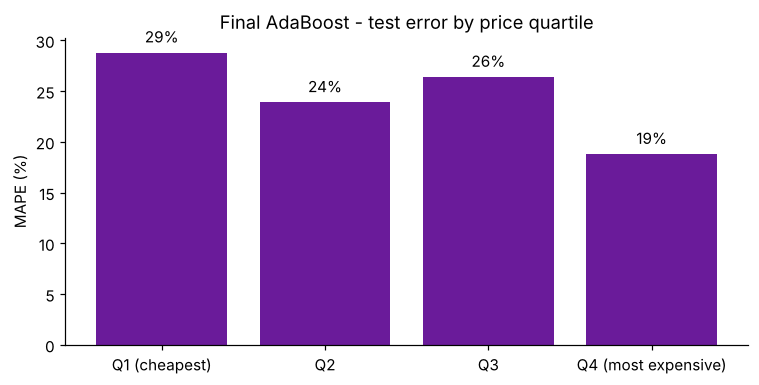

In [21]:
bands = pd.qcut(y_test, 4, labels=['Q1 (cheapest)', 'Q2', 'Q3', 'Q4 (most expensive)'])
band_tbl = pd.DataFrame({
    'Price range (USD)': y_test.groupby(bands).agg(lambda s: f'{s.min():,.0f} - {s.max():,.0f}'),
    'Final AdaBoost MAPE (%)': pd.Series(np.abs(final_test_pred - y_test) / y_test * 100, index=y_test.index).groupby(bands).mean().round(1),
    'Final AdaBoost MAE (USD)': pd.Series(np.abs(final_test_pred - y_test), index=y_test.index).groupby(bands).mean().round(0)})
display(band_tbl)
band_tbl.to_csv(MET_DIR / 'error_by_price_band.csv')

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(band_tbl.index.astype(str), band_tbl['Final AdaBoost MAPE (%)'], color='#6A1B9A')
for i, v in enumerate(band_tbl['Final AdaBoost MAPE (%)']): ax.text(i, v + 1, f'{v:.0f}%', ha='center')
ax.set_ylabel('MAPE (%)'); ax.set_title('Final AdaBoost - test error by price quartile')
plt.tight_layout(); plt.savefig(FIG_DIR / 'mape_by_price_band.png', bbox_inches='tight'); plt.show()

**Observation:** Relative error is worst for the cheapest quartile (28.8% MAPE, about USD 162 per stone) and best for the most expensive (18.8%, about USD 1,754 per stone). The model is least reliable in relative terms where most transactions happen.

# Conclusion

| | Test MAPE | Test R² |
|---|---|---|
| Baseline AdaBoost (default) | 42.2% | 0.875 |
| Tuned AdaBoost (lr 0.1, 50 trees, linear loss) | 24.5% | 0.883 |
| Single depth-3 tree | 23.2% | 0.876 |
| AdaBoost with depth-10 trees | 10.5% | 0.975 |
| HistGradientBoosting on log-price | 7.0% | 0.980 |

**Findings**
1. Tuning helped substantially by the selected metric (MAPE down 17.8 points), and neither model overfits.
2. With default stumps, AdaBoost does not beat a single tree of the same depth. Base-learner capacity, which the exercise grid left fixed, is the main lever.
3. The target scale matters: modelling log-price with gradient boosting gives 3.5x lower MAPE than the best tuned AdaBoost.

**Limitations:** One random 80/20 split, and the grid is deliberately small (2 CPU cores). One-hot encoding ignores the natural ordering of cut, colour and clarity; ordinal encoding would suit tree models better. Impurity importance is split across the correlated size features.